In [1]:
from pathlib import Path

data_dir = Path("data/Original CT Scans")

for class_folder in data_dir.iterdir():
    files = list(class_folder.glob("*.jpg"))
    print(class_folder.name, len(files))

nCT 9979
NiCT 5705
pCT 4001


(512, 512) RGB
(512, 512, 3)
37 255


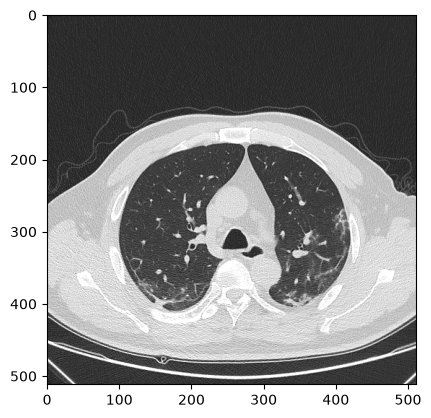

In [2]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

img = Image.open("data/Original CT Scans/pCT/pCT1005.jpg")
print(img.size, img.mode)

pixels = np.array(img)
print(pixels.shape)
print(pixels.min(), pixels.max())

plt.imshow(img, cmap="gray")
plt.show()

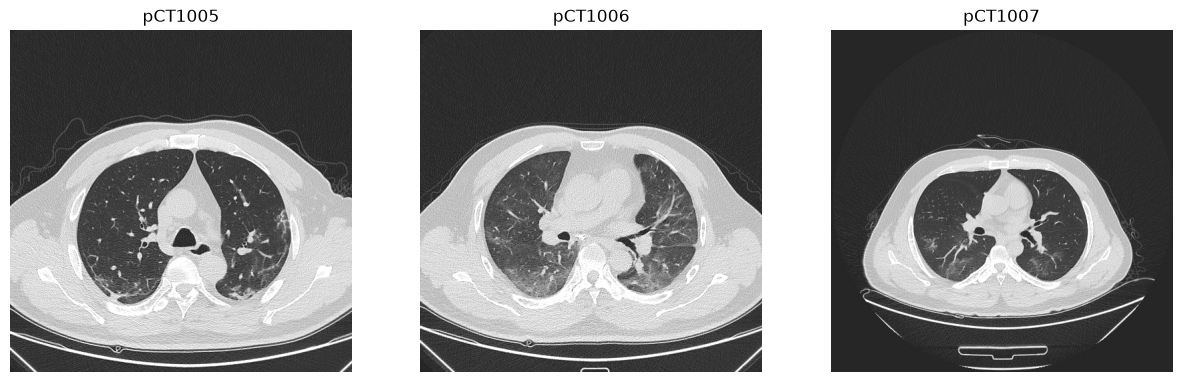

True


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, number in zip(axes, [1005, 1006, 1007]):
    img = Image.open(f"data/Original CT Scans/pCT/pCT{number}.jpg")
    ax.imshow(img, cmap="gray")
    ax.set_title(f"pCT{number}")
    ax.axis("off")

plt.show()

pixels = np.array(img)
print((pixels[:, :, 0] == pixels[:, :, 1]).all())

In [7]:
import random

rng = random.Random(42)
splits = {"train": [], "val": [], "test": []}

for class_folder in sorted(data_dir.iterdir(), key=lambda p: p.name):
    files = sorted(class_folder.glob("*.jpg"))
    rng.shuffle(files)

    n = len(files)
    n_train = int(n * 0.70)
    n_val = int(n * 0.15)

    splits["train"] += [(f, class_folder.name) for f in files[:n_train]]
    splits["val"] += [(f, class_folder.name) for f in files[n_train:n_train + n_val]]
    splits["test"] += [(f, class_folder.name) for f in files[n_train + n_val:]]

    print(class_folder.name, n_train, n_val, n - n_train - n_val)

for name, items in splits.items():
    print(name, len(items))

NiCT 3993 855 857
nCT 6985 1496 1498
pCT 2800 600 601
train 13778
val 2951
test 2956


In [8]:
from torchvision import transforms

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

img = Image.open(splits["train"][0][0]).convert("RGB")
x = eval_transform(img)

print(type(x))
print(x.shape)
print(x.min().item(), x.max().item())

<class 'torch.Tensor'>
torch.Size([3, 224, 224])
-2.1179039478302 2.640000104904175


In [9]:
from torch.utils.data import Dataset

class_names = ["NiCT", "nCT", "pCT"]
class_to_idx = {name: i for i, name in enumerate(class_names)}
print(class_to_idx)

class CTDataset(Dataset):
    def __init__(self, items, transform):
        self.items = items
        self.transform = transform

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        path, class_name = self.items[i]
        img = Image.open(path).convert("RGB")
        x = self.transform(img)
        y = class_to_idx[class_name]
        return x, y

val_ds = CTDataset(splits["val"], eval_transform)
print(len(val_ds))

x, y = val_ds[0]
print(x.shape, y)

{'NiCT': 0, 'nCT': 1, 'pCT': 2}
2951
torch.Size([3, 224, 224]) 0


In [10]:
from torch.utils.data import DataLoader

train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

train_ds = CTDataset(splits["train"], train_transform)
val_ds = CTDataset(splits["val"], eval_transform)
test_ds = CTDataset(splits["test"], eval_transform)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=16, shuffle=False, num_workers=0)

xb, yb = next(iter(train_loader))
print(xb.shape)
print(yb)
print(len(train_loader))

torch.Size([16, 3, 224, 224])
tensor([2, 0, 1, 1, 0, 0, 1, 1, 2, 0, 0, 1, 2, 1, 1, 2])
862


In [11]:
from torchvision import models

model = models.mobilenet_v3_large(weights="DEFAULT")
print(model.classifier)

n_params = sum(p.numel() for p in model.parameters())
print(f"{n_params:,} parameters")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to C:\Users\ravis/.cache\torch\hub\checkpoints\mobilenet_v3_large-5c1a4163.pth


100.0%


Sequential(
  (0): Linear(in_features=960, out_features=1280, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1280, out_features=1000, bias=True)
)
5,483,032 parameters


In [15]:
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

In [16]:
from torch import nn

model.classifier = nn.Sequential(
    nn.Linear(960, 1280),
    nn.ReLU(),
    nn.Dropout(p=0.2),
    nn.Linear(1280, 3),
)

n_params = sum(p.numel() for p in model.parameters())
print(f"{n_params:,} parameters")

device = torch.device("cuda")
model = model.to(device)

xb, yb = next(iter(train_loader))
xb = xb.to(device)

with torch.no_grad():
    out = model(xb)

print(out.shape)
print(out[:3])
print(out.softmax(dim=1)[:3])

4,205,875 parameters
torch.Size([16, 3])
tensor([[ 0.0763,  0.1235,  0.0452],
        [ 0.1591,  0.1345,  0.0071],
        [-0.0983, -0.0327,  0.0555]], device='cuda:0')
tensor([[0.3314, 0.3474, 0.3212],
        [0.3528, 0.3442, 0.3030],
        [0.3092, 0.3302, 0.3606]], device='cuda:0')


In [17]:
loss_fn = nn.CrossEntropyLoss()

yb = yb.to(device)
loss = loss_fn(out, yb)
print(loss.item())

1.0987319946289062


In [18]:
import math
print(math.log(3))

1.0986122886681098


In [19]:
import time

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

def evaluate(model, loader):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            total_loss += loss_fn(out, yb).item() * len(yb)
            correct += (out.argmax(dim=1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n

start = time.time()
model.train()

for step, (xb, yb) in enumerate(train_loader, 1):
    xb, yb = xb.to(device), yb.to(device)

    out = model(xb)
    loss = loss_fn(out, yb)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if step % 100 == 0:
        print(f"step {step}/{len(train_loader)}  loss {loss.item():.4f}  {time.time() - start:.0f}s")

val_loss, val_acc = evaluate(model, val_loader)
print(f"validation loss {val_loss:.4f}  accuracy {val_acc:.2%}")
print(f"total time {time.time() - start:.0f}s")

step 100/862  loss 0.4158  34s
step 200/862  loss 0.3109  67s
step 300/862  loss 0.0614  104s
step 400/862  loss 0.0691  138s
step 500/862  loss 0.1785  172s
step 600/862  loss 0.0949  206s
step 700/862  loss 0.0506  241s
step 800/862  loss 0.0529  274s
validation loss 0.0604  accuracy 98.10%
total time 356s


In [20]:
model = models.mobilenet_v3_large(weights="DEFAULT")
model.classifier = nn.Sequential(
    nn.Linear(960, 1280),
    nn.ReLU(),
    nn.Dropout(p=0.2),
    nn.Linear(1280, 3),
)
model = model.to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

Path("outputs").mkdir(exist_ok=True)
history = {"val_loss": [], "val_acc": []}
best_acc = 0.0
EPOCHS = 5

for epoch in range(1, EPOCHS + 1):
    start = time.time()
    model.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        loss = loss_fn(model(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    val_loss, val_acc = evaluate(model, val_loader)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), "outputs/best_model.pt")
        saved = "  saved"
    else:
        saved = ""

    print(f"epoch {epoch}/{EPOCHS}  val loss {val_loss:.4f}  val acc {val_acc:.2%}  {time.time() - start:.0f}s{saved}")

epoch 1/5  val loss 0.0372  val acc 98.85%  204s  saved
epoch 2/5  val loss 0.0252  val acc 99.12%  259s  saved
epoch 3/5  val loss 0.0310  val acc 98.98%  317s
epoch 4/5  val loss 0.0716  val acc 97.32%  300s
epoch 5/5  val loss 0.0198  val acc 99.25%  283s  saved


In [21]:
best_model = models.mobilenet_v3_large(weights=None)
best_model.classifier = nn.Sequential(
    nn.Linear(960, 1280),
    nn.ReLU(),
    nn.Dropout(p=0.2),
    nn.Linear(1280, 3),
)
best_model.load_state_dict(torch.load("outputs/best_model.pt"))
best_model = best_model.to(device)

test_loss, test_acc = evaluate(best_model, test_loader)
print(f"test loss {test_loss:.4f}  test accuracy {test_acc:.2%}")

test loss 0.0154  test accuracy 99.29%


In [22]:
all_preds, all_labels = [], []

best_model.eval()
with torch.no_grad():
    for xb, yb in test_loader:
        preds = best_model(xb.to(device)).argmax(dim=1).cpu()
        all_preds += preds.tolist()
        all_labels += yb.tolist()

matrix = [[0, 0, 0] for _ in range(3)]
for true, pred in zip(all_labels, all_preds):
    matrix[true][pred] += 1

print("true \\ pred", class_names)
for name, row in zip(class_names, matrix):
    print(f"{name:11s}", row)

true \ pred ['NiCT', 'nCT', 'pCT']
NiCT        [844, 11, 2]
nCT         [3, 1493, 2]
pCT         [3, 0, 598]


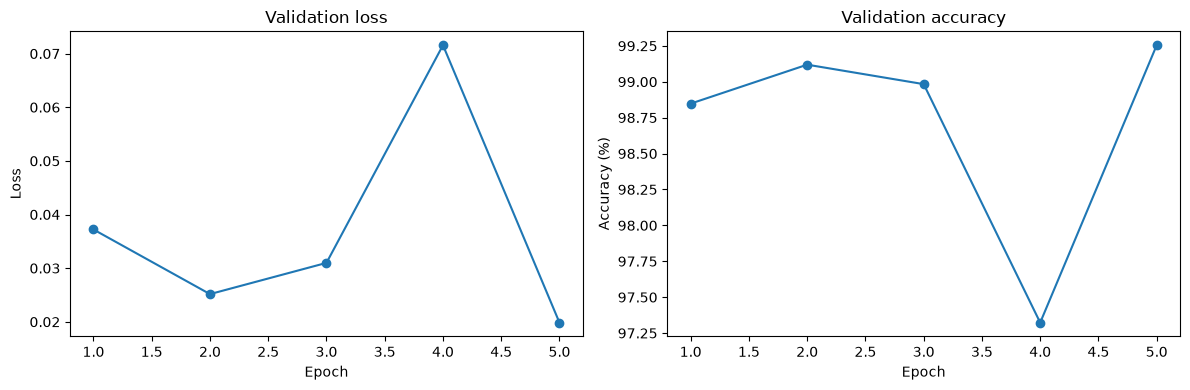

In [23]:
epochs = range(1, len(history["val_acc"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs, history["val_loss"], marker="o")
ax1.set_title("Validation loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")

ax2.plot(epochs, [a * 100 for a in history["val_acc"]], marker="o")
ax2.set_title("Validation accuracy")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")

plt.tight_layout()
plt.savefig("outputs/training_curves.png", dpi=150)
plt.show()

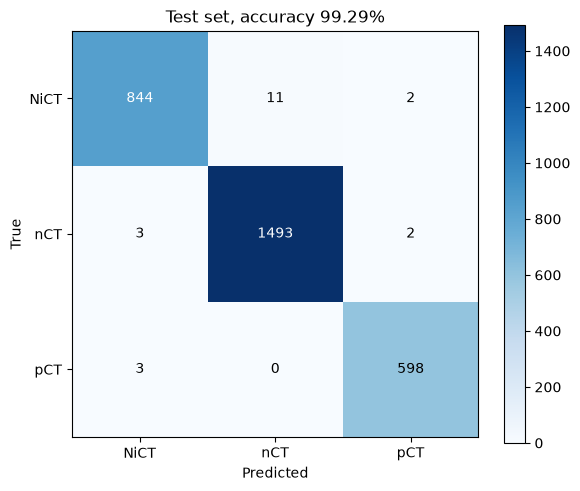

In [24]:
m = np.array(matrix)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(m, cmap="Blues")

ax.set_xticks(range(3), class_names)
ax.set_yticks(range(3), class_names)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title(f"Test set, accuracy {test_acc:.2%}")

for i in range(3):
    for j in range(3):
        color = "white" if m[i, j] > m.max() / 2 else "black"
        ax.text(j, i, m[i, j], ha="center", va="center", color=color)

fig.colorbar(im)
plt.tight_layout()
plt.savefig("outputs/confusion_matrix.png", dpi=150)
plt.show()